<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: Telecom Customer Churn Prediction</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Ingestion and Data Preprocessing (5 Marks)

Import standard data manipulation libraries. Load the Telco Customer Churn dataset directly from the provided raw URL into a pandas DataFrame. Immediately drop the `customerID` column, as unique text identifiers carry no predictive statistical power. Finally, convert the `TotalCharges` column to a numeric float data type, coercing any parsing errors to standard missing values, and impute these newly formed missing values with the statistical median of the column.

**Dataset URL:** `https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv`

**Hint:** Use the pandas read function, passing the URL directly. Utilize the drop method for columns, then the `pd.to_numeric` function with `errors='coerce'`, followed by the `fillna` method utilizing the median.

**Expected Output:** A pandas DataFrame displaying the initial rows of the dataset, with the unique ID column removed and the target financial column formatted as a continuous numeric type without missing values.

In [3]:
# Write your answer here
import pandas as pd
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df = df.drop("customerID", axis=1)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
print(df.head())
print(df.info())

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

### Question 2: Exploratory Data Analysis and Class Imbalance (7 Marks)

Assess the statistical distribution of the target variable `Churn`. Generate a bar chart or count plot to visually represent the frequencies of each class. Following the visualization, analyze how a significant class imbalance might artificially skew standard model accuracy metrics. Print your written answer using Python `print()` statements.

**Hint:** Use `value_counts()` in conjunction with a plotting library like seaborn or matplotlib to plot the class frequencies. Use `print()` to output a short paragraph discussing the accuracy paradox or the limitations of overall accuracy in imbalanced datasets.

**Expected Output:** A graphical plot illustrating the count of each churn category, followed by printed text analyzing the impact of class imbalance on standard classification evaluation.

Churn Class Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


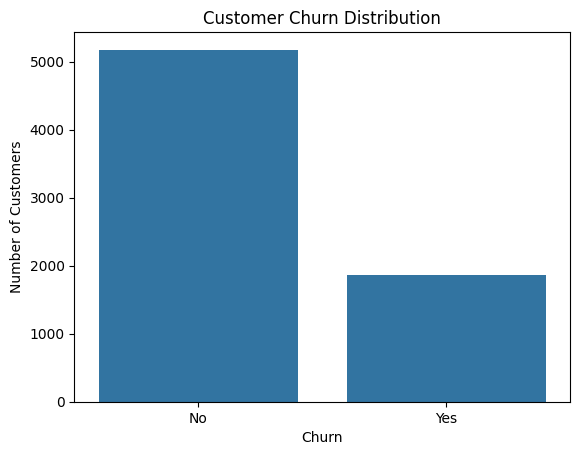


Analysis of Class Imbalance:
The dataset contains 5174 customers who did not churn and 1869 customers who churned.Therefore, the target classes are imbalanced, with non-churners forming the majority class. A model that predicts every customer as a non-churner would achieve approximately 73.46% accuracy but fail to identify any actual churners. This illustrates the accuracy paradox, where overall accuracy can be misleading for imbalanced datasets.Therefore, precision, recall, and ROC-AUC should also be considered when evaluating the model.


In [4]:
# Write your answer here
print("Churn Class Distribution:")
print(df["Churn"].value_counts())

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Churn", data=df)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

print("\nAnalysis of Class Imbalance:")
print(
    "The dataset contains 5174 customers who did not churn and 1869 customers who churned."
    "Therefore, the target classes are imbalanced, with non-churners forming the majority class."
    " A model that predicts every customer as a non-churner would achieve approximately 73.46% accuracy but fail to identify any actual churners. "
    "This illustrates the accuracy paradox, where overall accuracy can be misleading for imbalanced datasets."
    "Therefore, precision, recall, and ROC-AUC should also be considered when evaluating the model."
)

### Question 3: Feature Correlation and Target Encoding (6 Marks)

Encode the binary text values in the target `Churn` column to integers, converting 'Yes' statements to 1 and 'No' statements to 0. Next, isolate the primary continuous numeric features (`tenure`, `MonthlyCharges`, `TotalCharges`) and compute their Pearson correlation matrix against the newly encoded target variable. Interpret the results. Print your written answer using Python `print()` statements.

**Hint:** Use a dictionary mapping approach or the `replace` function to convert the target strings. Isolate the target and continuous features into a subset dataframe to calculate the standard correlation matrix. Use `print()` to write your analysis of which feature shows the strongest relationship.

**Expected Output:** The target column converted to binary integers, a numerical matrix displaying correlation coefficients, and printed text interpreting the strongest observed statistical relationship.

In [5]:
# Write your answer here
df["Churn"] = df["Churn"].replace({
    "Yes": 1,
    "No": 0
})

corr_df = df[
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

correlation_matrix = corr_df.corr(method="pearson")
print("Pearson Correlation Matrix:")
print(correlation_matrix)

churn_correlations = correlation_matrix["Churn"].drop("Churn")
strongest_feature = churn_correlations.abs().idxmax()
strongest_correlation = churn_correlations[strongest_feature]

print("\nCorrelation Analysis:")
print(
    f"The feature with the strongest Pearson correlation "
    f"with Churn is {strongest_feature}, with a correlation "
    f"coefficient of {strongest_correlation:.4f}."
)

if strongest_correlation > 0:
    print(
        "The relationship is positive, meaning higher values "
        "of this feature are associated with higher churn "
        "values in this dataset."
    )
elif strongest_correlation < 0:
    print(
        "The relationship is negative, meaning higher values "
        "of this feature are associated with lower churn "
        "values in this dataset."
    )
else:
    print("The observed linear correlation is zero.")

Pearson Correlation Matrix:
                  tenure  MonthlyCharges  TotalCharges     Churn
tenure          1.000000        0.247900      0.825464 -0.352229
MonthlyCharges  0.247900        1.000000      0.650864  0.193356
TotalCharges    0.825464        0.650864      1.000000 -0.199037
Churn          -0.352229        0.193356     -0.199037  1.000000

Correlation Analysis:
The feature with the strongest Pearson correlation with Churn is tenure, with a correlation coefficient of -0.3522.
The relationship is negative, meaning higher values of this feature are associated with lower churn values in this dataset.


/tmp/ipykernel_1652/2169720538.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Churn"] = df["Churn"].replace({


### Question 4: Categorical Encoding (5 Marks)

Transform all remaining text-based categorical columns (such as contract type, gender, or payment method) into binary dummy variables. Ensure you drop the first category of each feature during this process to prevent structural multicollinearity.

**Hint:** Utilize the `pd.get_dummies()` function. Ensure the parameter `drop_first=True` is explicitly set, and cast the resulting indicator columns to a standard numeric type (float or integer).

**Expected Output:** A fully numeric DataFrame expanded horizontally with indicator variables representing all unique categorical permutations.

In [6]:
# Write your answer here

df = pd.get_dummies(
    df,
    drop_first=True,
    dtype=int
)

print("Shape after categorical encoding:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print(
    "\nNumber of non-numeric columns:",
    df.select_dtypes(exclude="number").shape[1]
)

Shape after categorical encoding: (7043, 31)

First five rows:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0



Data types:
SeniorCitizen                              int64
tenure                                     int64
MonthlyCharges                           float64
TotalCharges                             float64
Churn                                      int64
gender_Male                                int64
Partner_Yes                                int64
Dependents_Yes                             int64
PhoneService_Yes                           int64
MultipleLines_No phone service             int64
MultipleLines_Yes                          int64
InternetService_Fiber optic                int64
InternetService_No                         int64
OnlineSecurity_No internet service         int64
OnlineSecurity_Yes                         int64
OnlineBackup_No internet service           int64
OnlineBackup_Yes                           int64
DeviceProtection_No internet service       int64
DeviceProtection_Yes                       int64
TechSupport_No internet service            int64
TechSup

### Question 5: Feature-Target Partition and Cross-Validation Split (5 Marks)

Separate the independent predictive features from the dependent target outcome. Following this separation, partition the data, assigning 80% of the records to the training set and the remaining 20% to the testing set. Apply stratification based on the target variable to ensure the class distribution remains proportional across splits. Set the random state configuration to 42.

**Hint:** Import `train_test_split` from `sklearn.model_selection`. Pass the feature matrix and target series. Set `test_size=0.20`, `random_state=42`, and utilize the `stratify` parameter using the target variable.

**Expected Output:** Four distinct programmatic variables successfully instantiated in memory, representing the training and testing features and targets, structured to reflect an 80/20 split preserving original class proportions.

In [7]:
# Write your answer here
from sklearn.model_selection import train_test_split

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nChurn proportions in the training set:")
print(y_train.value_counts(normalize=True).round(4))

print("\nChurn proportions in the testing set:")
print(y_test.value_counts(normalize=True).round(4))

Training features shape: (5634, 30)
Testing features shape: (1409, 30)
Training target shape: (5634,)
Testing target shape: (1409,)

Churn proportions in the training set:
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64

Churn proportions in the testing set:
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64


### Question 6: Feature Scaling and DataFrame Reconstruction (6 Marks)

Initialize a standard scaler object. Fit the scaler and transform the training features, then apply the transformation to normalize the testing features. Once scaled, explicitly convert both the resulting training and testing NumPy arrays back into pandas DataFrames, retaining the original column names for future interpretability.

**Hint:** Initialize `StandardScaler` from `sklearn.preprocessing`. Use `fit_transform` on the training subset and `transform` on the testing subset. Wrap the results in `pd.DataFrame()`, mapping the `columns` parameter to the original feature DataFrame's columns.

**Expected Output:** Two pandas DataFrames representing the training and testing features, standardized with means nearing zero and standard deviations of one, retaining all original column headers.

In [8]:
# Write your answer here
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    X_test_scaled,
    columns=X.columns,
    index=X_test.index
)

print("Training DataFrame shape:", X_train.shape)
print("Testing DataFrame shape:", X_test.shape)

print("\nFirst five rows of scaled training data:")
print(X_train.head())

print("\nColumn means of scaled training data (first five):")
print(X_train.mean().head().round(4))

print("\nColumn standard deviations of scaled training data (first five):")
print(X_train.std(ddof=0).head().round(4))

Training DataFrame shape: (5634, 30)
Testing DataFrame shape: (1409, 30)

First five rows of scaled training data:
      SeniorCitizen    tenure  MonthlyCharges  TotalCharges  gender_Male  \
3738      -0.441773  0.102371       -0.521976     -0.263289     0.994336   
3151      -0.441773 -0.711743        0.337478     -0.504814     0.994336   
4860      -0.441773 -0.793155       -0.809013     -0.751213     0.994336   
3867      -0.441773 -0.263980        0.284384     -0.173699    -1.005696   
3810      -0.441773 -1.281624       -0.676279     -0.990851     0.994336   

      Partner_Yes  Dependents_Yes  PhoneService_Yes  \
3738    -0.969234       -0.651557         -3.013090   
3151     1.031742        1.534786          0.331885   
4860     1.031742        1.534786         -3.013090   
3867     1.031742       -0.651557          0.331885   
3810     1.031742        1.534786          0.331885   

      MultipleLines_No phone service  MultipleLines_Yes  ...  \
3738                        3.013

### Question 7: Baseline Modeling and Evaluation (6 Marks)

Instantiate a baseline logistic regression model utilizing a fixed random seed of 42 and a maximum iteration limit of 1000. Fit this algorithm to the scaled training data and generate discrete predictions on the unseen test set. Compute and output the overall accuracy, precision, and recall by comparing predictions against the true test labels.

**Hint:** Import `LogisticRegression` from `sklearn.linear_model`. Fit it to the training data and generate predictions on the test set. Extract `accuracy_score`, `precision_score`, and `recall_score` from `sklearn.metrics` to evaluate performance.

**Expected Output:** Three decimal percentages printed to the console representing the baseline model's overall accuracy, precision, and recall on the test subset.

In [9]:
# Write your answer here
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print(f"Baseline Model Accuracy: {accuracy * 100:.3f}%")
print(f"Baseline Model Precision: {precision * 100:.3f}%")
print(f"Baseline Model Recall: {recall * 100:.3f}%")

Baseline Model Accuracy: 80.696%
Baseline Model Precision: 65.839%
Baseline Model Recall: 56.684%


### Question 8: Hyperparameter Tuning via Grid Search (8 Marks)

Execute hyperparameter tuning on the logistic regression model to optimize the inverse regularization strength (`C`). Configure a Grid Search with 5-fold cross-validation, testing at least three distinct values for `C` (e.g., 0.01, 0.1, 1.0, 10.0). Fit the Grid Search to the scaled training data and output the optimal parameters identified by the process.

**Hint:** Define a parameter grid dictionary mapping `'C'` to a list of values. Initialize `GridSearchCV` from `sklearn.model_selection`, passing the base model, parameter grid, and `cv=5`. Call the fit method and access the `best_params_` attribute.

**Expected Output:** A trained grid search object in memory and a printed statement displaying the optimal configuration for the hyperparameter `C` chosen by cross-validation.

In [10]:
# Write your answer here
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0]
}

base_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:",
      round(grid_search.best_score_ * 100, 3), "%")

Best Parameters: {'C': 10.0}
Best Cross-Validation Accuracy: 80.475 %


### Question 9: PyTorch Tensor Conversion and Dimensionality (5 Marks)

Import PyTorch. Convert the scaled training and testing feature DataFrames, along with their respective target series, into 32-bit floating-point tensor objects. Structurally reshape the two target tensors to enforce an explicit two-dimensional column vector representation (N rows by 1 column).

**Hint:** Import `torch`. Pass the underlying array values into `torch.tensor()`, specifying `dtype=torch.float32`. Utilize the `unsqueeze(1)` or `view(-1, 1)` method strictly on the target tensors to correct their dimensionality.

**Expected Output:** Four PyTorch tensors residing in memory. Shape evaluations on the target tensors will confirm a structure matching the total number of records by exactly one column.

In [11]:
# Write your answer here
import torch
X_train_tensor = torch.tensor(
    X_train.to_numpy(),
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test.to_numpy(),
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).unsqueeze(1)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).unsqueeze(1)

print("Training features tensor shape:", X_train_tensor.shape)
print("Testing features tensor shape:", X_test_tensor.shape)
print("Training target tensor shape:", y_train_tensor.shape)
print("Testing target tensor shape:", y_test_tensor.shape)

print("\nTensor data types:")
print("X_train_tensor:", X_train_tensor.dtype)
print("X_test_tensor:", X_test_tensor.dtype)
print("y_train_tensor:", y_train_tensor.dtype)
print("y_test_tensor:", y_test_tensor.dtype)

Training features tensor shape: torch.Size([5634, 30])
Testing features tensor shape: torch.Size([1409, 30])
Training target tensor shape: torch.Size([5634, 1])
Testing target tensor shape: torch.Size([1409, 1])

Tensor data types:
X_train_tensor: torch.float32
X_test_tensor: torch.float32
y_train_tensor: torch.float32
y_test_tensor: torch.float32


### Question 10: Custom PyTorch DataLoaders (6 Marks)

Construct PyTorch TensorDatasets for both the training and testing sets by combining their respective feature and target tensors. Following this, initialize DataLoaders for both datasets. Configure the data loaders to yield data in batch sizes of 64 samples per iteration, enabling shuffling exclusively for the training loader to optimize gradient descent.

**Hint:** Import `TensorDataset` and `DataLoader` from `torch.utils.data`. Combine the tensors into datasets, then pass them to data loaders specifying `batch_size=64`. Set `shuffle=True` only for the training loader argument.

**Expected Output:** Two configured DataLoader objects prepared to sequentially serve randomized batches of training data and ordered batches of testing data.

In [12]:
# Write your answer here
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

X_batch, y_batch = next(iter(train_loader))
print("Training feature batch shape:", X_batch.shape)
print("Training target batch shape:", y_batch.shape)

X_test_batch, y_test_batch = next(iter(test_loader))
print("Testing feature batch shape:", X_test_batch.shape)
print("Testing target batch shape:", y_test_batch.shape)

Training dataset size: 5634
Testing dataset size: 1409
Training batches: 89
Testing batches: 23
Training feature batch shape: torch.Size([64, 30])
Training target batch shape: torch.Size([64, 1])
Testing feature batch shape: torch.Size([64, 30])
Testing target batch shape: torch.Size([64, 1])


### Question 11: Multi-Layer Perceptron Architecture (8 Marks)

Define a custom object-oriented class representing a Multi-Layer Perceptron (MLP) inheriting from `nn.Module`. Design an input layer dynamically scaling to the feature dimensionality, mapping to a hidden layer of 32 nodes utilizing a Rectified Linear Unit (ReLU) activation. Connect this hidden layer to a final single output node regulated by a sigmoid activation function for bounded probabilistic outputs.

**Hint:** Import `torch.nn as nn`. Inside the `__init__` constructor, instantiate the linear transformations and activations. Outline the sequence of operations within an overridden `forward` method to process the input through the network.

**Expected Output:** An architecturally valid Python class blueprint, fully equipped to receive normalized numeric inputs and generate a bounded probability distribution between zero and one.

In [13]:
# Write your answer here
import torch.nn as nn
class MLP(nn.Module):
    def __init__(self, input_dim):
        super(MLP, self).__init__()

        self.input_layer = nn.Linear(input_dim, 32)
        self.relu = nn.ReLU()
        self.output_layer = nn.Linear(32, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.input_layer(x)
        x = self.relu(x)
        x = self.output_layer(x)
        x = self.sigmoid(x)
        return x

mlp = MLP(input_dim=X_train_tensor.shape[1])
print(mlp)
print("\nNumber of input features:", X_train_tensor.shape[1])
print("Hidden layer nodes:", 32)
print("Output layer nodes:", 1)

MLP(
  (input_layer): Linear(in_features=30, out_features=32, bias=True)
  (relu): ReLU()
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

Number of input features: 30
Hidden layer nodes: 32
Output layer nodes: 1


### Question 12: Loss Criterion and Optimizer Initialization (5 Marks)

Create an instance of the authored MLP class, passing the column count of the training features to dynamically set the input dimension. Instantiate a Binary Cross Entropy Loss criterion to measure divergence. Configure an Adam optimizer mapped to the network parameters, establishing a learning rate constraint of 0.001.

**Hint:** Extract the number of columns from your scaled feature DataFrame to initialize the network. Use `nn.BCELoss()` for the metric module and `torch.optim.Adam()` for the optimizer, passing in `model.parameters()`.

**Expected Output:** Three active computational objects instantiated in memory: the initialized network architecture, the operational loss function, and the Adam optimizer linked to the model weights.

In [14]:
# Write your answer here
import torch.optim as optim

model = MLP(input_dim=X_train.shape[1])

criterion = nn.BCELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model initialized:")
print(model)
print("\nLoss criterion:", criterion)
print("Optimizer:", optimizer)

Model initialized:
MLP(
  (input_layer): Linear(in_features=30, out_features=32, bias=True)
  (relu): ReLU()
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

Loss criterion: BCELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### Question 13: Neural Network Training Loop (10 Marks)

Construct a training loop programmed to iterate for exactly 50 epochs. During each epoch, process the training DataLoader batch by batch. For each batch, execute the standard sequence: clear existing gradients, compute forward model predictions, calculate the objective loss, propagate error gradients backwards, and step the optimizer. Accumulate and print the training loss value every 10 epochs.

**Hint:** Implement an outer loop over the epochs and an inner loop over the training DataLoader. Within the inner loop, call `optimizer.zero_grad()`, compute the outputs, calculate loss using the criterion, execute `loss.backward()`, and apply `optimizer.step()`.

**Expected Output:** Console output displaying a numeric training loss value periodically decreasing over time, confirming mathematical convergence of the network across the 50 iterations.

In [15]:
# Write your answer here
num_epochs = 50

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch + 1}/50], Training Loss: {epoch_loss:.4f}")

Epoch [10/50], Training Loss: 0.4086
Epoch [20/50], Training Loss: 0.3994
Epoch [30/50], Training Loss: 0.3940
Epoch [40/50], Training Loss: 0.3900
Epoch [50/50], Training Loss: 0.3867


### Question 14: MLP Evaluation and ROC-AUC (6 Marks)

Transition the neural network into evaluation mode and disable gradient computation to conserve memory. Pass the full testing feature tensor through the network to extract probabilistic predictions. Detach the result to a standard numpy array, then calculate and print the Area Under the Receiver Operating Characteristic Curve (ROC-AUC) utilizing the true testing labels.

**Hint:** Apply the `eval()` method to the model. Use a `with torch.no_grad():` context block. Pass the test features to the model, detach the output to numpy, and feed the true labels and predictions into the `roc_auc_score` function from `sklearn.metrics`.

**Expected Output:** A continuous decimal value representing the model's ranking performance, providing validation of its capability to distinguish between classes on the unseen test set.

In [16]:
# Write your answer here
from sklearn.metrics import roc_auc_score
model.eval()

with torch.no_grad():
    y_test_prob = model(X_test_tensor)

y_test_prob = y_test_prob.detach().cpu().numpy().ravel()

roc_auc = roc_auc_score(
    y_test.to_numpy(),
    y_test_prob
)

print(f"MLP ROC-AUC Score: {roc_auc:.4f}")

MLP ROC-AUC Score: 0.8393


### Question 15: Business Value and Campaign ROI (12 Marks)

Assume a business intervention campaign is launched targeting the test set cohort. The intervention costs $20 for every customer targeted. If the algorithm successfully targets a true churner (a True Positive), the business recovers $100 in saved revenue, yielding a net margin of +$80. If the algorithm erroneously targets an engaged customer (a False Positive), the $20 investment is wasted, yielding a net margin of -$20. Non-targeted customers carry zero direct campaign cost impacts.

Applying a probability threshold of 0.5 to the MLP predictions, isolate the True Positives and False Positives. Calculate the total absolute net financial return (profit or loss) incurred by deploying the algorithm. Print your logic and final dollar amount using Python `print()` statements.

**Hint:** Extract probability outputs from the test set. Apply a conditional threshold (`>= 0.5`) to classify outcomes. Compare these physically against the true testing labels to tally True Positives and False Positives. Multiply True Positives by 80 and False Positives by -20 to determine the cumulative margin.

**Expected Output:** A printed quantitative monetary value demonstrating the absolute net financial return of the retention campaign, accompanied by written text interpreting the logical outcome of applying the model to business operations.

In [18]:
# Write your answer here
import numpy as np
model.eval()

with torch.no_grad():
    churn_probabilities = model(X_test_tensor).cpu().numpy().ravel()

y_pred_campaign = (churn_probabilities >= 0.5).astype(int)

y_true_campaign = y_test.to_numpy()

true_positives = np.sum(
    (y_pred_campaign == 1) & (y_true_campaign == 1)
)

false_positives = np.sum(
    (y_pred_campaign == 1) & (y_true_campaign == 0)
)

tp_profit = true_positives * 80
fp_loss = false_positives * 20

net_return = tp_profit - fp_loss

print("True Positives:", true_positives)
print("False Positives:", false_positives)
print("Profit from True Positives: $", tp_profit)
print("Loss from False Positives: $", fp_loss)
print("Net Financial Return: $", net_return)

if net_return > 0:
    print("Business Outcome: The retention campaign generates a net profit.")
elif net_return < 0:
    print("Business Outcome: The retention campaign generates a net loss.")
else:
    print("Business Outcome: The retention campaign breaks even.")

True Positives: 187
False Positives: 111
Profit from True Positives: $ 14960
Loss from False Positives: $ 2220
Net Financial Return: $ 12740
Business Outcome: The retention campaign generates a net profit.
